[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_RQI_Mosaic_SpatialBias_DualPol/blob/main/notebooks/10_tmd_pipeline_step_by_step.ipynb)

# 10 · ระบบประมาณฝนเรดาร์ TMD ทีละขั้น: ทำ vs ไม่ทำ
*A step-by-step radar QPE pipeline for the TMD network: with vs without each step*

| | |
|---|---|
| **ระดับ** | 🟢 ป.ตรี ปี 3–4 และ 🔵 ป.โท |
| **เวลาโดยประมาณ** | 150 นาที |
| **ควรผ่านมาก่อน** | 04, 07, 08, 09 |
| **ข้อมูลเข้า** | UF 5 เรดาร์ × 2 ชั่วโมง (คำนวณสด 2 รอบ ~6–8 นาที), ฝนสถานี สสน. |
| **ผลลัพธ์** | ค่าปรับเทียบ Z ระหว่างเรดาร์, แผนที่ 7 ขั้น, ตาราง metrics แบบบันได + ablation, ทดสอบข้ามชั่วโมง |

> 📌 **วิธีใช้:** กด *Runtime ▸ Run all* ได้ทันที หรือรันทีละเซลล์ (Shift+Enter) พร้อมอ่านคำอธิบาย
> เซลล์ที่มีหัวข้อ 🔑 เป็นเฉลยที่ซ่อนไว้ ลองทำแบบฝึกหัดก่อนแล้วค่อยเปิดดู

## 🎯 วัตถุประสงค์การเรียนรู้
1. **ปรับเทียบ** reflectivity ระหว่างเรดาร์จากพื้นที่ซ้อนทับ (Gourley et al. 2003) และอ่านผลแบบ loop closure
2. **ประกอบ** ระบบประมาณฝน 5 ขั้นตามลำดับ และเทียบกับวิธีที่ใช้อยู่ (Mahavik et al. 2025)
3. **ประเมินอย่างยุติธรรม** เมื่อขั้นตอนใช้สถานีฝน: leave-one-gauge-out และทดสอบข้ามชั่วโมง
4. **แยกผล** ของแต่ละขั้นด้วยการ "เพิ่มทีละขั้น" (ladder) และ "ตัดออกทีละขั้น" (ablation)
5. **บอกข้อจำกัด** ของข้อสรุปจากข้อมูล 2 ชั่วโมงได้ถูกต้อง

## 1. ระบบที่จะทดสอบ

| ขั้น | ทำอะไร | ถ้าไม่ทำ | อ้างอิงหลัก |
|---|---|---|---|
| **1** ปรับเทียบ Z ระหว่างเรดาร์ | หา offset (dB) ของแต่ละเรดาร์จากพื้นที่ซ้อนทับ แล้วลบออกจาก Z | ใช้ Z ตามที่เรดาร์รายงาน | Gourley, Kaney & Maddox (2003); Crisologo & Heistermann (2020); Hu et al. (2025) |
| **2** Polarimetric hybrid scan | มุมยกต่ำสุดที่ไม่ถูกบัง + R(KDP)/R(A) ใต้ชั้นหลอมเหลว | CAPPI 2 กม. + Z–R | Fulton et al. (1998); Ryzhkov et al. (2005; 2014); Giangrande & Ryzhkov (2008) |
| **3** โมเสคด้วย RQI | $\sum \text{RQI}_iR_i/\sum\text{RQI}_i$ | ค่าสูงสุด (MAX) | Zhang et al. (2011; 2016) |
| **4** MFB ทั้งโดเมน | $F=\sum G/\sum R$ จากทุกสถานี (ค่าเดียว) | ไม่ปรับ / ปรับรายเรดาร์ | Seo et al. (1999); Chumchean et al. (2006) |
| **5** ปรับแก้เชิงพื้นที่ | IDW ของ $\ln\frac{G+\varepsilon}{R+\varepsilon}$ รอบ MFB | ใช้ MFB อย่างเดียว | Goudenhoofdt & Delobbe (2009); notebook 08 |

**จุดตั้งต้น S0 = วิธีใน Mahavik et al. (2025)**: CAPPI 2 กม. → Z = 250R<sup>1.2</sup> (Rosenfeld tropical) →
**MFB รายเรดาร์** $F_i = \overline{G}/\overline{R_i}$ จากสถานีในรัศมี 240 กม. → โมเสค **MAX**
(โค้ดต้นฉบับ: github.com/nattaponm/RadarRainfallMosaic-TH)

| รหัส | ประกอบด้วย |
|---|---|
| S0 | CAPPI-RT + MFB รายเรดาร์ + MAX (ตามบทความ, ไม่จำกัดค่า F) |
| S0r | เหมือน S0 แต่ F ทนทานขึ้น: ใช้คู่ที่มีฝน ≥ 0.1 มม., ≥ 5 คู่, จำกัด 0.2–5 |
| R0 | CAPPI-RT + MAX (ไม่ปรับอะไร) |
| R1 | R0 + ขั้น 1 |
| R2 | R1 + ขั้น 2 |
| R3 | R2 + ขั้น 3 |
| R4 | R3 + ขั้น 4 |
| R5 | R4 + ขั้น 5 (ครบทุกขั้น) |

### ⚠️ ข้อจำกัดที่ต้องรู้ก่อนเริ่ม
- **ข้อมูลเรดาร์มีเพียง 2 ชั่วโมงที่ไม่ต่อเนื่อง** (00 และ 10 UTC) — MFB แบบ "หน้าต่างเวลาเลื่อน" ทำจริงไม่ได้
  จึงใช้ (ก) MFB ในชั่วโมงเดียวกันแบบ **leave-one-gauge-out** และ (ข) **ทดสอบข้ามชั่วโมง** (ใช้ค่าจาก 00 UTC กับ 10 UTC และกลับกัน)
- บทความต้นฉบับคำนวณ $F_i$ จากเหตุการณ์ 10 วัน — ค่าจาก 1 ชั่วโมงจะผันผวนกว่ามาก ผล S0 ที่นี่ **ไม่ใช่การประเมินความแม่นของบทความ** แต่แสดงว่าวิธีนี้ไวต่อขนาดตัวอย่างอย่างไร
- ไฟล์ UF ของรายวิชามี 2–5 มุมยกต่อเรดาร์ (CRI, PHS มีเพียง 2) — CAPPI 2 กม. จึงเป็น **pseudo-CAPPI** เกือบทั้งหมด
- การปรับเทียบจากพื้นที่ซ้อนทับให้ได้ **ค่าสัมพัทธ์** (ใครสูง/ต่ำกว่าเพื่อน) ระดับสัมบูรณ์มาจาก MFB (ขั้น 4) หรือ GPM

In [1]:
PACKAGES = ('teaching_data', 'products')
#@title ⚙️ เตรียมสภาพแวดล้อม (รันเซลล์นี้ก่อนทุกครั้ง) { display-mode: "form" }
import os, sys, subprocess
REPO, OWNER = "Teach_RQI_Mosaic_SpatialBias_DualPol", "nattaponm"
if "google.colab" in sys.modules:
    if not os.path.exists(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        f"https://github.com/{OWNER}/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
else:  # running on your own computer: move to the repository root
    while not os.path.exists("config/study_area.yaml") and os.getcwd() != os.path.dirname(os.getcwd()):
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
from radteach import colab
P = colab.setup(packages=PACKAGES)

installing: arm_pyart (about 1–2 minutes the first time) …
downloading teaching_data_v1.zip …
teaching_data_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
downloading teaching_products_v1.zip …
teaching_products_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
repository : /content/Teach_RQI_Mosaic_SpatialBias_DualPol
Colab      : True
Thai font  : Sarabun
data       : /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw


## 2. รอบที่ 1: ค่ารายเรดาร์โดยยังไม่ปรับเทียบ (~3–4 นาที)
`keep_sweeps=True` เก็บ Z ของ **ทุกมุมยก** บนกริด เพื่อใช้จับคู่ความสูงลำคลื่นในขั้นที่ 1

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from radteach import io, dem, mosaic, calib, pipeline, bias, verify, gauges as gg, config, plotting as pl, mapping as mp
cfg = config.load_all(); g = cfg["study_area"]["grid"]
glon, glat = mosaic.make_grid(g["lon_min"], g["lon_max"], g["lat_min"], g["lat_max"], g["res_deg"])
z, tr, _ = dem.read(P.products / "dem_study_area.tif"); terrain = dem.interpolator(z, tr)
HOURS = {"00UTC": "2024-10-03 00:00", "10UTC": "2024-10-03 10:00"}
DROP = ["radar_LS_DP", "radar_HYZ_MP", "radar_rqi_HYZ", "radar_LS_MP", "radar_rqi_LS"]   # not needed here
def run(offsets=None):
    out = {}
    for h in HOURS:
        scans = io.list_scans(P.radar / f"20241003_{h}")
        cal = pd.read_csv(P.products / f"calibration_20241003_{h}.csv", index_col=0)
        r = mosaic.process_hour(scans, terrain, cal, glon, glat, keep_radars=True, keep_sweeps=offsets is None,
                                z_offset_db=offsets, verbose=False)
        for k in DROP: r.pop(k, None)
        out[h] = r; print("  ", h, "เสร็จ")
    return out
raw = run()
RADARS = [str(x) for x in raw["00UTC"]["radars"]]
for rd in RADARS:
    sw = np.isfinite(raw["00UTC"]["radar_hgt_SW"][RADARS.index(rd)]).any((1, 2)).sum()
    print(f"{rd}: {sw} มุมยก")

   00UTC เสร็จ
   10UTC เสร็จ
CRI: 2 มุมยก
LMP: 4 มุมยก
MHS: 5 มุมยก
PHS: 2 มุมยก
TAK: 4 มุมยก


## 3. ขั้นที่ 1 — ปรับเทียบ Z จากพื้นที่ซ้อนทับ

### 3.1 หลักการ (Gourley et al. 2003)
ถ้าเรดาร์ $i$ และ $j$ วัดฝน **ก้อนเดียวกัน ที่ความสูงเดียวกัน ด้วยปริมาตรลำคลื่นใกล้กัน** ค่า Z ควรเท่ากัน
ความต่างที่เหลือคือความต่างของการปรับเทียบ $\Delta Z_{ij} = c_i - c_j$

| เกณฑ์ | Gourley (2003) | ของเรา (`calib.DEFAULTS`) | เหตุผล |
|---|---|---|---|
| ห่างแนวนอน | < 500 ม. | เซลล์กริดเดียวกัน (1 กม.) | เราทำบนกริดร่วม |
| ความสูงลำคลื่น | ต่าง < 50 ม. (ข้ามมุมยกได้) | ต่าง ≤ 250 ม. (เลือกคู่มุมยกที่ใกล้สุดทุกเซลล์) | กริดหยาบกว่า; TAK อยู่สูง 943 ม. แต่ PHS 72 ม. |
| ปริมาตรลำคลื่น | ต่าง < 5% | แถบห่างเท่ากัน $|d_i-d_j| ≤ 30$ กม. | Crisologo & Heistermann (2020) ใช้ 10 กม. |
| การบัง | ใช้ hybrid scan | CBB ≤ 0.2 ทั้งคู่ | Crisologo et al. (2018) |
| bright band | — | ขอบบนลำคลื่นต่ำกว่าฐาน ML − 300 ม. | ฝนน้ำแข็ง/หลอมเหลวให้ Z ต่างตามมุมมอง |
| Z | ≥ 15 dBZ | 15–45 dBZ | Hu et al. (2025) ใช้ 15–35 |
| ค่าผิดปกติ | |ΔZ| ≤ 8 dB | ≤ 8 dB + ตัด 3σ | Gourley; Hu et al. |
| เวลา | < 3 นาที | สแกนช่องเวลาเดียวกัน (15 นาที) | TMD สแกนพร้อมกันตามรอบ |

**แก้ระบบสมการทั้งเครือข่าย** (ส่วนที่เราเพิ่ม): $\min \sum_{(i,j)} n_{ij}\left(\Delta Z_{ij} - (c_i - c_j)\right)^2$ ภายใต้ $\sum c = 0$
ในแต่ละกลุ่มเรดาร์ที่เชื่อมกัน แล้วตรวจ **loop closure** $\Delta Z_{ab}+\Delta Z_{bc}+\Delta Z_{ca}\approx 0$

In [3]:
pp = []
for h in HOURS:
    p = calib.overlap_pairs(raw[h]); p["hour"] = h; p["scan_id"] = h + "_" + p.scan.astype(str); pp.append(p)
pairs_z = pd.concat(pp, ignore_index=True)
st = calib.pair_stats(pairs_z)
groups = calib.components(st)
offsets = calib.solve_offsets(st, RADARS)
boot = calib.bootstrap_offsets(pairs_z, RADARS, n_boot=300)
ci = boot.quantile([0.025, 0.975]).T.rename(columns={0.025: "lo", 0.975: "hi"})
st.round(2).to_csv(P.tables / "10_overlap_pair_stats.csv", index=False)
print("คู่เรดาร์ที่ใช้ได้:"); display(st.round(2))
print("กลุ่มเรดาร์ที่เชื่อมกัน:", groups)
lc = calib.loop_closure(st)
print("loop closure:", "ไม่มีสามเหลี่ยมที่ครบ 3 คู่" if lc.empty else ""); display(lc.round(2)) if not lc.empty else None
OFF = pd.DataFrame({"offset_dB": offsets, "CI_lo": ci.lo, "CI_hi": ci.hi})
OFF["หาได้ไหม"] = np.where(OFF.offset_dB.notna(), "ได้ (สัมพัทธ์ในกลุ่ม)", "ไม่ได้ — ไม่มีคู่")
OFF.round(2).to_csv(P.tables / "10_z_offsets.csv"); OFF.round(2)

คู่เรดาร์ที่ใช้ได้:


,radar_i,radar_j,n,median,mean,iqr,std,used
0,CRI,LMP,83,1.01,1.22,4.24,3.33,True
1,PHS,TAK,178,3.27,2.86,5.41,3.34,True


กลุ่มเรดาร์ที่เชื่อมกัน: [['CRI', 'LMP'], ['PHS', 'TAK']]
loop closure: ไม่มีสามเหลี่ยมที่ครบ 3 คู่


,offset_dB,CI_lo,CI_hi,หาได้ไหม
CRI,0.51,0.17,1.02,ได้ (สัมพัทธ์ในกลุ่ม)
LMP,-0.51,-1.02,-0.17,ได้ (สัมพัทธ์ในกลุ่ม)
MHS,NaN,NaN,NaN,ไม่ได้ — ไม่มีคู่
PHS,1.64,1.07,2.32,ได้ (สัมพัทธ์ในกลุ่ม)
TAK,-1.64,-2.32,-1.07,ได้ (สัมพัทธ์ในกลุ่ม)


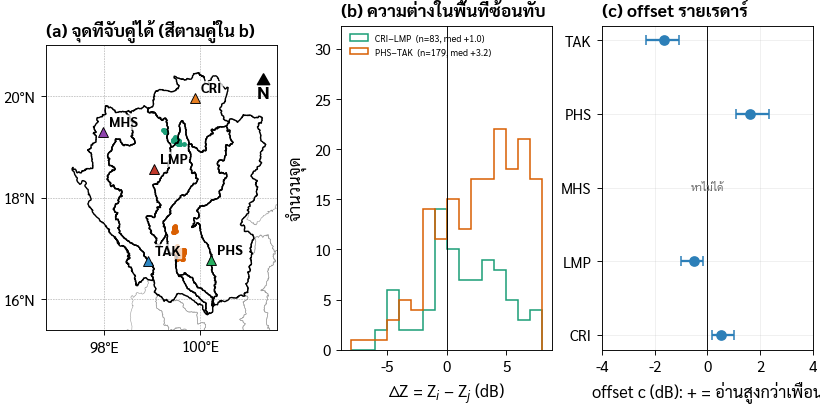

In [4]:
from matplotlib.lines import Line2D
E = cfg["study_area"]["map_extent"]["north"]
fig, (ax0, ax1, ax2) = pl.subplots(1, 3, width="double", height_mm=95, gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
pc = dict(zip(sorted(set(zip(st.radar_i, st.radar_j))), ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02"]))
for (a, b), d in pairs_z.groupby(["radar_i", "radar_j"]):
    ax0.scatter(glon[d.ix], glat[d.iy], s=5, color=pc[(a, b)], zorder=6, rasterized=True)
mp.basemap(ax0, E, title="(a) จุดที่จับคู่ได้ (สีตามคู่ใน b)", scale_km=None, grid_step=2)
bins = np.arange(-8, 8.5, 1)
for (a, b), d in pairs_z.groupby(["radar_i", "radar_j"]):
    ax1.hist(d.dz, bins, histtype="step", lw=1.3, color=pc[(a, b)], label=f"{a}−{b}  (n={len(d)}, med {d.dz.median():+.1f})")
ax1.axvline(0, color="k", lw=0.6); ax1.set_xlabel("ΔZ = Z$_i$ − Z$_j$ (dB)"); ax1.set_ylabel("จำนวนจุด")
ax1.set_title("(b) ความต่างในพื้นที่ซ้อนทับ", loc="left", fontweight="bold"); ax1.set_ylim(0, ax1.get_ylim()[1] * 1.4)
ax1.legend(fontsize=6, loc="upper left")
ok = OFF.offset_dB.notna()
y = np.arange(len(OFF))
ax2.errorbar(OFF.offset_dB[ok], y[ok], xerr=[OFF.offset_dB[ok] - OFF.CI_lo[ok], OFF.CI_hi[ok] - OFF.offset_dB[ok]],
             fmt="o", color="#2c7fb8", capsize=3, label="จากพื้นที่ซ้อนทับ (95% CI)")
for k in y[~ok]: ax2.text(0, k, "หาไม่ได้", ha="center", va="center", fontsize=7, color="0.4")
ax2.axvline(0, color="k", lw=0.6); ax2.set_yticks(y); ax2.set_yticklabels(OFF.index); ax2.set_xlabel("offset c (dB): + = อ่านสูงกว่าเพื่อน")
ax2.set_title("(c) offset รายเรดาร์", loc="left", fontweight="bold"); ax2.set_xlim(-4, 4); ax2.grid(alpha=0.3, lw=0.4)
pl.save(fig, "10_overlap_calibration"); plt.show()

**อ่านผล (ข้อมูลชุดนี้):**
- ได้คู่ที่ใช้ได้เพียง **CRI–LMP** และ **PHS–TAK** เท่านั้น — ไม่มีสามเหลี่ยมให้ตรวจ loop closure
  เพราะ LMP มีมุมยกต่ำสุด 1.59° ลำคลื่นที่กึ่งกลาง LMP–PHS จึงอยู่สูงใกล้ชั้นหลอมเหลวและถูกตัดทิ้ง ส่วน MHS (มุมต่ำสุด 3°) ไม่มีคู่เลย
- **TAK อ่านต่ำกว่า PHS ~3 dB** — สอดคล้องกับที่ notebook 09 พบว่า factor จากสถานีของ TAK ใหญ่ผิดปกติ
- offset ที่ได้เป็น **ค่าสัมพัทธ์ในกลุ่ม** (CRI/LMP คู่หนึ่ง, PHS/TAK อีกคู่หนึ่ง) เทียบข้ามกลุ่มไม่ได้ — ระดับร่วมจะถูกแก้ด้วย MFB ในขั้น 4
- ระบบปฏิบัติการต้องใช้ข้อมูล **หลายสัปดาห์–หลายเดือน** (Gourley ใช้หลายพันคู่ต่อคู่เรดาร์) จึงจะได้เครือข่ายที่เชื่อมกันครบและตรวจ loop closure ได้

### 3.2 ผลต่อฝน
การลบ offset $c$ ออกจาก Z ทำให้ฝนจาก Z–R เปลี่ยน $R' = R\cdot10^{-c/(10b)}$ — ตัวประมาณที่ใช้เฟส (R(KDP)) ไม่เปลี่ยน

In [5]:
eff = pd.DataFrame({"offset_dB": OFF.offset_dB.fillna(0),
                    "ค่าคูณฝน Rosenfeld (b=1.2)": calib.rain_factor(OFF.offset_dB.fillna(0), 1.2),
                    "ค่าคูณฝน Marshall–Palmer (b=1.6)": calib.rain_factor(OFF.offset_dB.fillna(0), 1.6)}).round(3)
display(eff)
del pairs_z, boot
for h in raw:                                  # free memory: the sweep cubes are no longer needed
    for k in ["radar_dbz_SW", "radar_hgt_SW", "radar_cbb_SW"]: raw[h].pop(k, None)
OFFSETS = OFF.offset_dB.fillna(0).to_dict()
print("รอบที่ 2: ประมวลผลใหม่โดยลบ offset ออกจาก Z (~3 นาที)")
calz = run(OFFSETS)

,offset_dB,ค่าคูณฝน Rosenfeld (b=1.2),ค่าคูณฝน Marshall–Palmer (b=1.6)
CRI,0.506,0.907,0.930
LMP,-0.506,1.102,1.076
MHS,0.000,1.000,1.000
PHS,1.635,0.731,0.790
TAK,-1.635,1.369,1.265


รอบที่ 2: ประมวลผลใหม่โดยลบ offset ออกจาก Z (~3 นาที)
   00UTC เสร็จ
   10UTC เสร็จ


## 4. ประกอบระบบทีละขั้นและประเมินที่สถานี
- ทุกค่าที่สถานี = ค่าเฉลี่ยหน้าต่าง 3×3 (เหมือน notebook 07–09)
- ขั้นที่ใช้สถานี (S0, R4, R5 และ ablation) คำนวณแบบ **leave-one-gauge-out**: ค่าที่สถานี $s$ มาจาก factor ที่ไม่ใช้สถานี $s$

In [6]:
meta = gg.read_metadata(P.stations / "hii_station_metadata_202410.csv")
gq = gg.add_utc(gg.quality_control(gg.read_station_csv(P.stations / "hii_hourly_rain_20241003_0519LT.csv"), meta=meta))
pts = {}
for h, t0 in HOURS.items():
    d = gq[(gq.start_utc == t0) & (gq.qc == "OK")].merge(meta[["station_code", "longitude", "latitude", "basin"]], on="station_code")
    pts[h] = d.rename(columns={"longitude": "lon", "latitude": "lat", "rain_qc": "G"})[["station_code", "start_utc", "lon", "lat", "G", "basin"]].reset_index(drop=True)
at = lambda res, prod, meth, d, scale=None: pipeline.mosaic_at_points(res, prod, meth, d.lon.values, d.lat.values, scale=scale)
def loo(d, vals, method, **kw):
    return bias.loocv(d.assign(X=vals), "X", methods=(method,), **kw)[method].values
ROBUST = dict(wet=0.1, min_n=5, fmin=0.2, fmax=5.0)
rows, FAC = [], {}
for h in HOURS:
    d = pts[h].copy()
    Rp = pipeline.per_radar_at_points(raw[h], "CAPPI_RT", d.lon.values, d.lat.values)
    FAC[h] = pd.DataFrame({"F_บทความ": pipeline.per_radar_mfb(d.G.values, Rp, loo=False),
                           "F_ทนทาน": pipeline.per_radar_mfb(d.G.values, Rp, loo=False, **ROBUST),
                           "สถานีที่เห็น": np.isfinite(Rp).sum(0)}, index=RADARS)
    d["S0"] = at(raw[h], "CAPPI_RT", "MAX", d, pipeline.per_radar_mfb(d.G.values, Rp, loo=True))
    d["S0r"] = at(raw[h], "CAPPI_RT", "MAX", d, pipeline.per_radar_mfb(d.G.values, Rp, loo=True, **ROBUST))
    d["R0"] = at(raw[h], "CAPPI_RT", "MAX", d)
    d["R1"] = at(calz[h], "CAPPI_RT", "MAX", d)
    d["R2"] = at(calz[h], "PHY_DP", "MAX", d)
    d["R3"] = at(calz[h], "PHY_DP", "RQI_WMEAN", d)
    d["R4"] = loo(d, d.R3.values, "mfb")
    d["R5"] = loo(d, d.R3.values, "idw")
    d["−ปรับเทียบ Z"] = loo(d, at(raw[h], "PHY_DP", "RQI_WMEAN", d), "idw")
    d["−pol. hybrid"] = loo(d, at(calz[h], "CAPPI_RT", "RQI_WMEAN", d), "idw")
    d["−RQI (ใช้ MAX)"] = loo(d, d.R2.values, "idw")
    d["−MFB"] = loo(d, d.R3.values, "idw", mfb_background=False)
    d["−เชิงพื้นที่"] = d.R4
    rows.append(d)
pairs = pd.concat(rows, ignore_index=True)
print("factor รายเรดาร์ของ S0 (ใช้ทุกสถานี)"); display(pd.concat(FAC, axis=1).round(2))

factor รายเรดาร์ของ S0 (ใช้ทุกสถานี)


00UTC                         10UTC                     
    F_บทความ F_ทนทาน สถานีที่เห็น F_บทความ F_ทนทาน สถานีที่เห็น
CRI     5.22    5.00          104    11.45    5.00          116
LMP     6.37    5.00          140    10.73    5.00          158
MHS     1.00    1.00           86  1457.45    5.00           86
PHS     3.27    3.28          121     2.99    3.01          122
TAK    32.78    5.00          101    32.86    5.00          108

In [7]:
LADDER = ["S0", "S0r", "R0", "R1", "R2", "R3", "R4", "R5"]
ABL = ["R5", "−ปรับเทียบ Z", "−pol. hybrid", "−RQI (ใช้ MAX)", "−MFB", "−เชิงพื้นที่"]
CFG = list(dict.fromkeys(LADDER + ABL))
common = pairs.dropna(subset=CFG)
COLS = ["n", "PBIAS", "RMSE", "r", "r_wet", "KGE", "POD", "FAR", "CSI"]
def mtab(df, keys):
    t = pd.DataFrame({k: verify.metrics(df.G, df[k]) for k in keys}).T.reindex(columns=COLS)
    t["CSI≥5มม."] = [verify.metrics(df.G, df[k], thr=5).get("CSI") for k in keys]
    return t
TL = mtab(common, LADDER); TA = mtab(common, ABL)
TL.round(2).to_csv(P.tables / "10_metrics_ladder.csv"); TA.round(2).to_csv(P.tables / "10_metrics_ablation.csv")
pairs.to_csv(P.tables / "10_pairs.csv", index=False, encoding="utf-8-sig")
print(f"คู่ข้อมูลชุดเดียวกัน n = {len(common)}  (2 ชั่วโมง)"); display(TL.round(2)); display(TA.round(2))

คู่ข้อมูลชุดเดียวกัน n = 358  (2 ชั่วโมง)


,n,PBIAS,RMSE,r,r_wet,KGE,POD,FAR,CSI,CSI≥5มม.
S0,358.0,274.24,7.20,0.42,0.27,-3.01,0.85,0.42,0.53,0.14
S0r,358.0,112.23,5.37,0.17,-0.02,-1.19,0.78,0.38,0.52,0.19
R0,358.0,-42.24,2.41,0.12,-0.09,0.01,0.52,0.30,0.42,0.00
R1,358.0,-53.62,2.15,0.17,-0.06,-0.07,0.46,0.34,0.37,0.00
R2,358.0,-61.98,1.76,0.52,0.29,-0.03,0.54,0.26,0.45,0.00
R3,358.0,-71.12,1.72,0.72,0.57,-0.08,0.52,0.20,0.46,0.00
R4,358.0,3.16,1.34,0.74,0.63,0.70,0.76,0.29,0.58,0.33
R5,358.0,-12.93,0.98,0.87,0.83,0.73,0.70,0.37,0.50,0.36


,n,PBIAS,RMSE,r,r_wet,KGE,POD,FAR,CSI,CSI≥5มม.
R5,358.0,-12.93,0.98,0.87,0.83,0.73,0.70,0.37,0.50,0.36
−ปรับเทียบ Z,358.0,-9.38,1.06,0.84,0.79,0.77,0.69,0.38,0.48,0.31
−pol. hybrid,358.0,-14.44,1.26,0.77,0.71,0.62,0.70,0.44,0.45,0.25
−RQI (ใช้ MAX),358.0,-0.77,1.69,0.63,0.51,0.63,0.67,0.39,0.47,0.31
−MFB,358.0,-20.46,1.41,0.70,0.60,0.54,0.69,0.35,0.50,0.27
−เชิงพื้นที่,358.0,3.16,1.34,0.74,0.63,0.70,0.76,0.29,0.58,0.33


### 4.1 ความไม่แน่นอน: bootstrap รายสถานี

In [8]:
rng = np.random.default_rng(7)
by = [d for _, d in common.groupby("station_code")]
B = {k: [] for k in CFG}
for _ in range(400):
    s = pd.concat([by[i] for i in rng.integers(0, len(by), len(by))])
    for k in CFG:
        m = verify.metrics(s.G, s[k]); B[k].append((m["PBIAS"], m["RMSE"], m.get("r_wet", np.nan), m.get("CSI", np.nan)))
CI = {k: np.nanpercentile(np.array(v), [2.5, 97.5], axis=0) for k, v in B.items()}

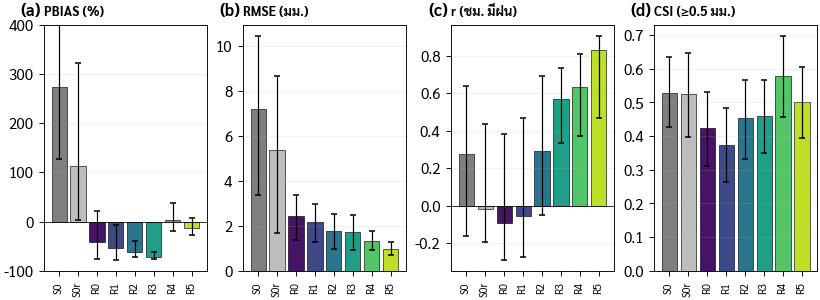

In [9]:
fig, axs = pl.subplots(1, 4, width="double", height_mm=70)
x = np.arange(len(LADDER)); col = ["#7f7f7f", "#bdbdbd"] + list(plt.get_cmap("viridis")(np.linspace(0.05, 0.9, 6)))
for j, (met, lab) in enumerate([("PBIAS", "PBIAS (%)"), ("RMSE", "RMSE (มม.)"), ("r_wet", "r (ชม. มีฝน)"), ("CSI", "CSI (≥0.5 มม.)")]):
    ax = axs[j]; v = TL[met].values
    lo = np.array([CI[k][0, j] for k in LADDER]); hi = np.array([CI[k][1, j] for k in LADDER])
    ax.bar(x, v, color=col, edgecolor="k", lw=0.4)
    ax.errorbar(x, v, yerr=[v - lo, hi - v], fmt="none", ecolor="k", lw=0.8, capsize=2)
    ax.set_xticks(x); ax.set_xticklabels(LADDER, rotation=90, fontsize=7); ax.set_title(lab, loc="left", fontweight="bold", fontsize=8.5)
    ax.axhline(0, color="k", lw=0.5); ax.grid(alpha=0.3, lw=0.4, axis="y")
    if met == "PBIAS": ax.set_ylim(-100, max(120, np.nanmax(hi) * 1.05) if np.nanmax(hi) < 400 else 400)
pl.panel_labels(axs); pl.save(fig, "10_metrics_ladder"); plt.show()

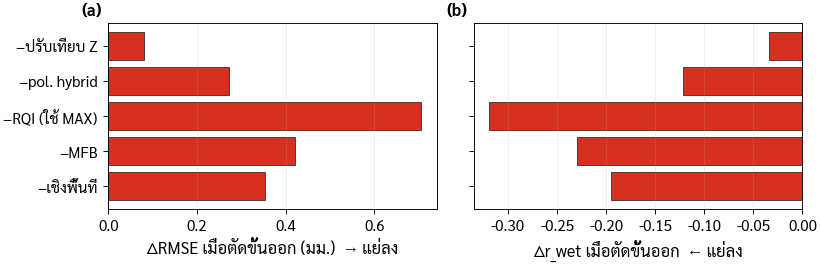

In [10]:
fig, axs = pl.subplots(1, 2, width="double", height_mm=62)
ref = TA.loc["R5"]; labs = ABL[1:]; y = np.arange(len(labs))
for ax, met, lab in [(axs[0], "RMSE", "ΔRMSE เมื่อตัดขั้นออก (มม.)  → แย่ลง"), (axs[1], "r_wet", "Δr_wet เมื่อตัดขั้นออก  ← แย่ลง")]:
    dv = TA.loc[labs, met] - ref[met]
    ax.barh(y, dv, color=["#d7301f" if (v > 0) == (met == "RMSE") else "#2b8cbe" for v in dv], edgecolor="k", lw=0.4)
    ax.set_yticks(y); ax.set_yticklabels(labs); ax.axvline(0, color="k", lw=0.6); ax.invert_yaxis()
    ax.set_xlabel(lab); ax.grid(alpha=0.3, lw=0.4, axis="x")
axs[1].set_yticklabels([])
pl.panel_labels(axs); pl.save(fig, "10_ablation"); plt.show()

## 5. แผนที่แต่ละขั้น (10 UTC) — ใช้สถานีทั้งหมดในการปรับ (ไม่ใช่ leave-one-out)

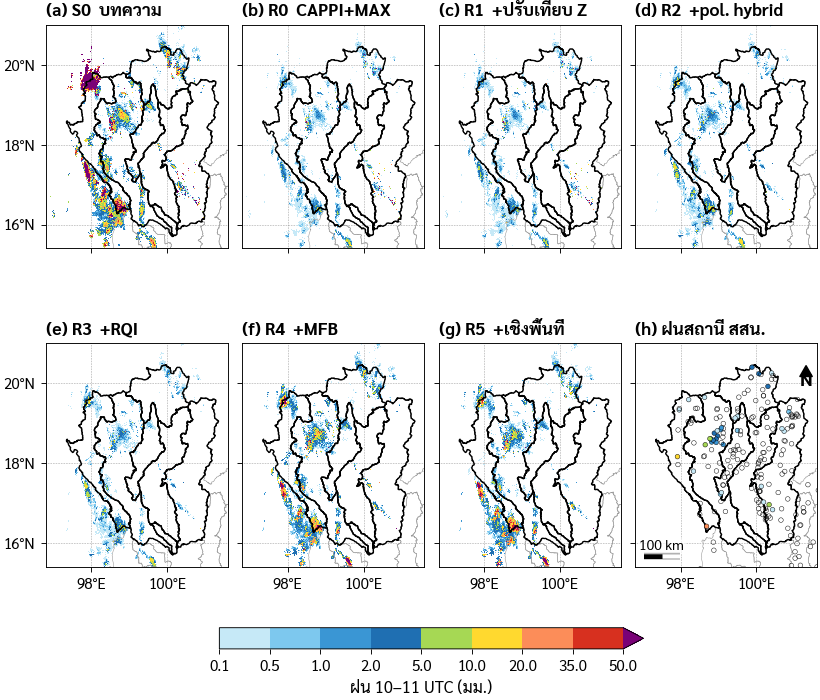

In [11]:
h = "10UTC"; d = pts[h]
def scaled(res, prod, F):
    r = dict(res); r[f"radar_{prod}"] = res[f"radar_{prod}"] * np.asarray(F)[:, None, None, None]; return r
r3 = mosaic.combine_hour(calz[h], "PHY_DP", "RQI_WMEAN")
r3_at = verify.sample(r3, glon, glat, d.lon, d.lat, 3)
FIELDS = {
    "S0  บทความ": mosaic.combine_hour(scaled(raw[h], "CAPPI_RT", FAC[h]["F_บทความ"].values), "CAPPI_RT", "MAX"),
    "R0  CAPPI+MAX": mosaic.combine_hour(raw[h], "CAPPI_RT", "MAX"),
    "R1  +ปรับเทียบ Z": mosaic.combine_hour(calz[h], "CAPPI_RT", "MAX"),
    "R2  +pol. hybrid": mosaic.combine_hour(calz[h], "PHY_DP", "MAX"),
    "R3  +RQI": r3,
    "R4  +MFB": bias.adjust_field(r3, glon, glat, d.lon, d.lat, d.G.values, r3_at, method="mfb")[0],
    "R5  +เชิงพื้นที่": bias.adjust_field(r3, glon, glat, d.lon, d.lat, d.G.values, r3_at, method="idw")[0],
}
cm, nm = pl.rain_cmap()
fig, axs = pl.subplots(2, 4, width="double", height_mm=175)
for ax, (lab, f), L in zip(axs.ravel(), FIELDS.items(), "abcdefg"):
    im = mp.show_grid(ax, f, glon, glat, cm, nm)
    mp.basemap(ax, E, title=f"({L}) {lab}", scale_km=None, north=False, grid_step=2, radars=False)
    ax.title.set_fontsize(8)
ax = axs.ravel()[-1]
ax.scatter(d.lon, d.lat, c=d.G, cmap=cm, norm=nm, s=9, edgecolor="k", lw=0.3, zorder=7)
mp.basemap(ax, E, title="(h) ฝนสถานี สสน.", scale_km=100, grid_step=2, radars=False); ax.title.set_fontsize(8)
for a in axs[:, 1:].ravel(): a.set_yticklabels([])
for a in axs[0].ravel(): a.set_xticklabels([])
fig.colorbar(im, ax=axs, orientation="horizontal", shrink=0.55, extend="max").set_label("ฝน 10–11 UTC (มม.)")
pl.save(fig, "10_maps_each_step"); plt.show()

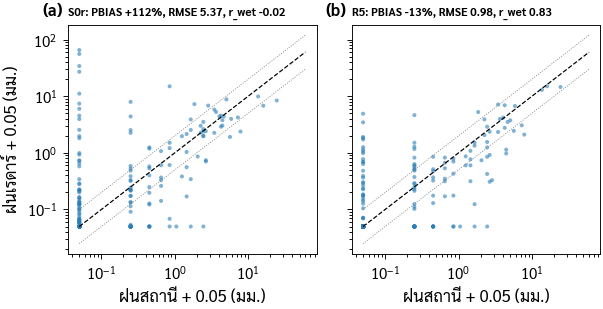

In [12]:
fig, axs = pl.subplots(1, 2, width="one_half", height_mm=72, sharex=True, sharey=True)
for ax, k in zip(axs, ["S0r", "R5"]):
    ax.scatter(common.G + 0.05, common[k] + 0.05, s=7, alpha=0.6, color="#2c7fb8", edgecolor="none")
    ax.set_xscale("log"); ax.set_yscale("log"); pl.one_to_one(ax, 0.05, 60)
    m = TL.loc[k]; ax.set_title(f"{k}: PBIAS {m.PBIAS:+.0f}%, RMSE {m.RMSE:.2f}, r_wet {m.r_wet:.2f}", loc="left", fontsize=7.5, fontweight="bold")
    ax.set_xlabel("ฝนสถานี + 0.05 (มม.)")
axs[0].set_ylabel("ฝนเรดาร์ + 0.05 (มม.)")
pl.panel_labels(axs); pl.save(fig, "10_scatter_S0r_R5"); plt.show()

## 6. ทดสอบข้ามชั่วโมง: factor ที่หาจากชั่วโมงหนึ่ง ใช้กับอีกชั่วโมงได้ไหม
ในงานปฏิบัติการ factor ต้องหาจาก **อดีต** แล้วใช้กับ **ปัจจุบัน** — ทดสอบด้วยการสลับ 00 ↔ 10 UTC

In [13]:
other = {"00UTC": "10UTC", "10UTC": "00UTC"}
xs = []
for h in HOURS:
    d = pts[h].copy(); o = pts[other[h]]
    Rp_o = pipeline.per_radar_at_points(raw[other[h]], "CAPPI_RT", o.lon.values, o.lat.values)
    d["S0 ข้ามชม."] = at(raw[h], "CAPPI_RT", "MAX", d, pipeline.per_radar_mfb(o.G.values, Rp_o, loo=False))
    d["S0r ข้ามชม."] = at(raw[h], "CAPPI_RT", "MAX", d, pipeline.per_radar_mfb(o.G.values, Rp_o, loo=False, **ROBUST))
    Fd, _ = bias.mean_field_factor(o.G.values, at(calz[other[h]], "PHY_DP", "RQI_WMEAN", o))
    d["R4 ข้ามชม."] = at(calz[h], "PHY_DP", "RQI_WMEAN", d) * Fd
    print(f"factor ทั้งโดเมนจาก {other[h]} ใช้กับ {h}: {Fd:.2f}")
    xs.append(d)
X = pd.concat(xs, ignore_index=True).merge(pairs[["station_code", "start_utc", "S0", "S0r", "R4"]], on=["station_code", "start_utc"])
KX = ["S0", "S0 ข้ามชม.", "S0r", "S0r ข้ามชม.", "R4", "R4 ข้ามชม."]
TX = mtab(X.dropna(subset=KX), KX); TX.round(2).to_csv(P.tables / "10_metrics_cross_hour.csv"); TX.round(2)

factor ทั้งโดเมนจาก 10UTC ใช้กับ 00UTC: 5.47
factor ทั้งโดเมนจาก 00UTC ใช้กับ 10UTC: 2.78


,n,PBIAS,RMSE,r,r_wet,KGE,POD,FAR,CSI,CSI≥5มม.
S0,362.0,274.24,7.16,0.42,0.27,-3.01,0.85,0.42,0.53,0.14
S0 ข้ามชม.,362.0,196.78,5.43,0.43,0.29,-1.86,0.80,0.44,0.49,0.17
S0r,362.0,112.23,5.34,0.17,-0.02,-1.19,0.78,0.38,0.52,0.19
S0r ข้ามชม.,362.0,104.00,5.19,0.17,-0.01,-1.09,0.78,0.38,0.52,0.19
R4,362.0,3.16,1.33,0.74,0.63,0.70,0.76,0.29,0.58,0.33
R4 ข้ามชม.,362.0,34.95,1.89,0.61,0.47,0.46,0.74,0.38,0.51,0.24


## 7. ฝนเฉลี่ยรายลุ่มน้ำ (10 UTC)

In [14]:
from rasterio.features import rasterize
from rasterio.transform import from_origin
mb, sb, _ = mp.boundaries()
T_ = from_origin(glon[0] - 0.005, glat[0] + 0.005, 0.01, 0.01)
zones = {r.MBASIN_E: rasterize([(r.geometry, 1)], out_shape=(len(glat), len(glon)), transform=T_).astype(bool)
         for _, r in mb[mb.MB_CODE.isin(["06", "07", "08", "09"])].iterrows()}
_hw = sb[sb.SB_CODE.isin(cfg["study_area"]["ping_headwater_subbasins"])].geometry
zones["Ping headwater"] = rasterize([((_hw.union_all() if hasattr(_hw, "union_all") else _hw.unary_union), 1)],
                                    out_shape=(len(glat), len(glon)), transform=T_).astype(bool)
BM = pd.DataFrame({lab: {zn: np.nanmean(f[zm]) for zn, zm in zones.items()} for lab, f in FIELDS.items()})
BM.round(3).to_csv(P.tables / "10_basin_means_10UTC.csv"); BM.round(3)

,S0 บทความ,R0 CAPPI+MAX,R1 +ปรับเทียบ Z,R2 +pol. hybrid,R3 +RQI,R4 +MFB,R5 +เชิงพื้นที่
Ping,3.072,0.287,0.303,0.282,0.254,1.389,1.016
Wang,0.843,0.070,0.076,0.049,0.039,0.212,0.129
Yom,0.170,0.046,0.034,0.012,0.007,0.037,0.015
Nan,1.453,0.474,0.347,0.030,0.026,0.141,0.075
Ping headwater,1.561,0.145,0.157,0.129,0.125,0.684,0.346


## 8. สรุปและแปลผล (ตัวเลขจากการรันตอนสร้างบทเรียน — ตรวจกับตารางของนิสิต)

| | S0 | S0r | R0 | R1 | R2 | R3 | R4 | R5 |
|---|---|---|---|---|---|---|---|---|
| PBIAS (%) | +274 | +112 | −42 | −54 | −62 | −71 | **+3** | −13 |
| RMSE (มม.) | 7.2 | 5.3 | 2.4 | 2.2 | 1.8 | 1.7 | 1.3 | **1.0** |
| r_wet | 0.27 | −0.02 | −0.09 | −0.06 | 0.29 | 0.57 | 0.63 | **0.83** |

1. **S0 (MFB รายเรดาร์ + MAX) ให้ฝนเกินมาก** แม้ทำ F ให้ทนทานแล้ว (S0r +112%) สาเหตุมี 2 ชั้น:
   - F ที่หาจาก 1 ชั่วโมงผันผวนมาก (MHS ได้ ~1,457 เพราะ CAPPI ของ MHS แทบไม่เห็นฝนที่สถานี)
   - **ค่าสูงสุดของหลายค่าที่ไม่เอนเอียง ย่อมเอนเอียงไปทางสูงเสมอ** (แบบฝึกหัด 3) — การปรับรายเรดาร์แล้วเลือก MAX จึงเกินอย่างเป็นระบบ
2. **ขั้น 1 (ปรับเทียบ Z) ให้ผลเล็กในข้อมูลชุดนี้** (offset ±1.6 dB, ablation แทบไม่ต่าง) — ไม่ได้แปลว่าไม่สำคัญ:
   ข้อมูลน้อยจนเชื่อมเครือข่ายไม่ครบ และ R(KDP) ไม่ขึ้นกับการปรับเทียบ Z อยู่แล้ว
3. **ขั้น 2 และ 3 ให้ r เพิ่มมากที่สุด** (r_wet −0.06 → 0.29 → 0.57) — รูปแบบเชิงพื้นที่ถูกต้องขึ้น แต่ฝนยังต่ำ (PBIAS −71%)
4. **ขั้น 4 แก้ bias รวม** (−71% → +3%) — ทำได้ดีเพราะขั้น 1–3 ทำให้รูปแบบถูกก่อน ค่าคูณเดียวจึงพอ
5. **ขั้น 5 ลด RMSE ต่อ** (1.3 → 1.0) และ r_wet 0.83 แลกกับ PBIAS −13% (IDW ใน log space ดึงค่าสูงลง)
6. **Ablation**: ตัด RQI ออกแย่ที่สุด (RMSE 1.0 → 1.7) รองลงมาคือ MFB, เชิงพื้นที่ และ pol. hybrid; ตัดการปรับเทียบ Z ออกแทบไม่ต่าง (+0.08 มม.)
7. **ข้ามชั่วโมง**: MFB ทั้งโดเมนยังพอใช้ได้ (R4: PBIAS +35%) แต่ MFB รายเรดาร์ใช้ไม่ได้ (S0: +197%) — factor รายเรดาร์ต้องหาจากหน้าต่างเวลายาวและมีขีดจำกัด
8. **ข้อจำกัด**: 2 ชั่วโมง, ~360 คู่, ความไม่แน่นอนกว้าง (ดูแถบ CI) — ต้องยืนยันด้วยทั้งเหตุการณ์และหลายเหตุการณ์

---
## ✏️ แบบฝึกหัด

### แบบฝึกหัด 1 · 🟢 ป.ตรี

จากตาราง `st` คำนวณ offset ของ PHS และ TAK **ด้วยมือ** (กลุ่มที่มี 2 เรดาร์ และ Σc = 0) แล้วแปลงเป็นค่าคูณฝนสำหรับ Z–R แบบ Rosenfeld (b = 1.2) และ Marshall–Palmer (b = 1.6) — แบบไหนไวต่อการปรับเทียบมากกว่า

In [15]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
dz_pt = st.set_index(["radar_i", "radar_j"]).loc[("PHS", "TAK"), "median"]
c_phs = None; c_tak = None; f_rt = None; f_mp = None

In [16]:
#@title 🔑 เฉลยข้อ 1 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
c_phs, c_tak = dz_pt / 2, -dz_pt / 2
f_rt = 10 ** (-c_tak / (10 * 1.2)); f_mp = 10 ** (-c_tak / (10 * 1.6))
print(f"ΔZ(PHS−TAK) = {dz_pt:+.2f} dB → c_PHS = {c_phs:+.2f}, c_TAK = {c_tak:+.2f} dB")
print(f"ฝนของ TAK ถูกคูณ {f_rt:.2f} (Rosenfeld) หรือ {f_mp:.2f} (MP)")
print("b เล็ก (Rosenfeld 1.2) → R ไวต่อ Z มากกว่า: ความผิดพลาด 1 dB ทำให้ฝนเปลี่ยน ~21% เทียบกับ ~15% ของ MP")
assert abs(c_phs - offsets["PHS"]) < 0.05

ΔZ(PHS−TAK) = +3.27 dB → c_PHS = +1.64, c_TAK = -1.64 dB
ฝนของ TAK ถูกคูณ 1.37 (Rosenfeld) หรือ 1.27 (MP)
b เล็ก (Rosenfeld 1.2) → R ไวต่อ Z มากกว่า: ความผิดพลาด 1 dB ทำให้ฝนเปลี่ยน ~21% เทียบกับ ~15% ของ MP


### แบบฝึกหัด 2 · 🟢 ป.ตรี

จากกราฟ ablation เรียงลำดับขั้นที่ "ขาดไม่ได้" จากมากไปน้อย (ตาม RMSE) และอธิบายว่าทำไมการตัดการปรับเทียบ Z ออกจึงแทบไม่มีผลในข้อมูลชุดนี้ (อย่างน้อย 2 เหตุผล)

In [17]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
rank = None

In [18]:
#@title 🔑 เฉลยข้อ 2 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
rank = (TA.loc[ABL[1:], "RMSE"] - TA.loc["R5", "RMSE"]).sort_values(ascending=False)
display(rank.round(3).rename("ΔRMSE"))
print("เหตุผล: (1) offset ที่หาได้เล็ก (±1.6 dB) และหาได้เพียง 4 เรดาร์ในสองกลุ่มแยกกัน; "
      "(2) PHY_DP ใช้ R(KDP) ในฝนหนักซึ่งไม่ขึ้นกับการปรับเทียบ Z; (3) MFB และ IDW ในขั้น 4–5 ดูดซับ bias ที่เหลือ")

,ΔRMSE
−RQI (ใช้ MAX),0.706
−MFB,0.421
−เชิงพื้นที่,0.354
−pol. hybrid,0.273
−ปรับเทียบ Z,0.081


เหตุผล: (1) offset ที่หาได้เล็ก (±1.6 dB) และหาได้เพียง 4 เรดาร์ในสองกลุ่มแยกกัน; (2) PHY_DP ใช้ R(KDP) ในฝนหนักซึ่งไม่ขึ้นกับการปรับเทียบ Z; (3) MFB และ IDW ในขั้น 4–5 ดูดซับ bias ที่เหลือ


### แบบฝึกหัด 3 · 🟢 ป.ตรี

**ทำไม MAX ของค่าที่ไม่เอนเอียงจึงเอนเอียง?** จำลองฝนจริง R = 5 มม. วัดด้วยเรดาร์ n = 1–5 ตัวที่ไม่เอนเอียงแต่มีความคลาดเคลื่อนสุ่มแบบ lognormal (σ = 0.5 ใน ln) แล้วหาค่าเฉลี่ยของ MAX และ MEAN

In [19]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
sim = None

In [20]:
#@title 🔑 เฉลยข้อ 3 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
rng_ = np.random.default_rng(0); s_ = 0.5
rows_ = []
for n in range(1, 6):
    X_ = 5 * np.exp(rng_.normal(-s_**2 / 2, s_, size=(100000, n)))     # unbiased: E[X] = 5
    rows_.append({"เรดาร์ซ้อนทับ": n, "MEAN": X_.mean(1).mean(), "MAX": X_.max(1).mean()})
sim = pd.DataFrame(rows_).set_index("เรดาร์ซ้อนทับ"); sim["MAX เกิน (%)"] = 100 * (sim.MAX / 5 - 1); display(sim.round(2))
print("แม้ทุกเรดาร์ไม่เอนเอียงหลังปรับ F_i แล้ว MAX ก็เกินจริงขึ้นตามจำนวนเรดาร์ที่ซ้อนทับ — นี่คือกลไกที่ทำให้ S0/S0r ได้ PBIAS เป็นบวก")

,MEAN,MAX,MAX เกิน (%)
เรดาร์ซ้อนทับ,,,
1,5.00,5.00,-0.05
2,5.00,6.39,27.85
3,5.01,7.26,45.12
4,5.00,7.87,57.30
5,5.00,8.35,67.02


แม้ทุกเรดาร์ไม่เอนเอียงหลังปรับ F_i แล้ว MAX ก็เกินจริงขึ้นตามจำนวนเรดาร์ที่ซ้อนทับ — นี่คือกลไกที่ทำให้ S0/S0r ได้ PBIAS เป็นบวก


### แบบฝึกหัด 4 · 🔵 ป.โท / ส่วนขยาย

🔵 ความไวของ offset ต่อเกณฑ์จับคู่: ลอง `max_dd_km` = 20, 30, 40 และ `max_cbb` = 0.1, 0.2, 0.3 (ต้องรันส่วนที่ 2 ใหม่ด้วย `keep_sweeps=True` เพราะลบไปแล้ว — หรือทำก่อนส่วน 3.2) ค่า PHS−TAK เปลี่ยนเท่าไร ควรเลือกเกณฑ์อย่างไร

In [21]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
sens = None

In [22]:
#@title 🔑 เฉลยข้อ 4 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
print("ต้องมี raw ที่ยังเก็บ radar_dbz_SW — ถ้าลบไปแล้วให้รัน raw = run() ใหม่ (~3 นาที)")
if "radar_dbz_SW" not in raw["00UTC"]:
    raw = run()
rows_ = []
for dd in [20, 30, 40]:
    for cb in [0.1, 0.2, 0.3]:
        p_ = pd.concat([calib.overlap_pairs(raw[h], max_dd_km=dd, max_cbb=cb) for h in HOURS])
        s_ = calib.pair_stats(p_); o_ = calib.solve_offsets(s_, RADARS)
        r_ = s_.set_index(["radar_i", "radar_j"])
        rows_.append({"max_dd_km": dd, "max_cbb": cb, "n PHS–TAK": int(r_.n.get(("PHS", "TAK"), 0)),
                      "ΔZ PHS−TAK": r_["median"].get(("PHS", "TAK"), np.nan), "กลุ่ม": calib.components(s_)})
sens = pd.DataFrame(rows_); display(sens.round(2))
print("เกณฑ์หลวม → จุดมากขึ้นแต่ปนความต่างของปริมาตรลำคลื่นและการบัง; เกณฑ์เข้ม → ค่าแม่นแต่จุดน้อย ควรเลือกจากความเสถียรของค่า + จำนวนจุดขั้นต่ำ")

ต้องมี raw ที่ยังเก็บ radar_dbz_SW — ถ้าลบไปแล้วให้รัน raw = run() ใหม่ (~3 นาที)
   00UTC เสร็จ
   10UTC เสร็จ


,max_dd_km,max_cbb,n PHS–TAK,ΔZ PHS−TAK,กลุ่ม
0,20,0.1,176,3.18,"[[PHS, TAK]]"
1,20,0.2,176,3.18,"[[CRI, LMP], [PHS, TAK]]"
2,20,0.3,176,3.18,"[[CRI, LMP], [PHS, TAK]]"
3,30,0.1,178,3.27,"[[CRI, LMP], [PHS, TAK]]"
4,30,0.2,178,3.27,"[[CRI, LMP], [PHS, TAK]]"
5,30,0.3,178,3.27,"[[CRI, LMP], [PHS, TAK]]"
6,40,0.1,178,3.27,"[[CRI, LMP], [PHS, TAK]]"
7,40,0.2,178,3.27,"[[CRI, LMP], [PHS, TAK]]"
8,40,0.3,184,3.41,"[[CRI, LMP], [PHS, TAK]]"


เกณฑ์หลวม → จุดมากขึ้นแต่ปนความต่างของปริมาตรลำคลื่นและการบัง; เกณฑ์เข้ม → ค่าแม่นแต่จุดน้อย ควรเลือกจากความเสถียรของค่า + จำนวนจุดขั้นต่ำ


### แบบฝึกหัด 5 · 🔵 ป.โท / ส่วนขยาย

🔵 ขั้น 5 ไวต่อรัศมี IDW แค่ไหน: ลอง `radius_km` = 25, 50, 100 ใน `bias.loocv(..., radius_km=...)` กับ R3 แล้วดู RMSE, PBIAS และ r_wet

In [23]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
rad_tab = None

In [24]:
#@title 🔑 เฉลยข้อ 5 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
rows_ = []
for rk in [25, 50, 100]:
    v_ = []
    for h in HOURS:
        dd_ = pairs[pairs.start_utc == HOURS[h]]
        v_.append(pd.Series(loo(dd_.reset_index(drop=True), dd_.R3.values, "idw", radius_km=rk)))
    vv = pd.concat(v_, ignore_index=True).values
    m_ = verify.metrics(pairs.G.values, vv)
    rows_.append({"radius_km": rk, "RMSE": m_["RMSE"], "PBIAS": m_["PBIAS"], "r_wet": m_.get("r_wet")})
rad_tab = pd.DataFrame(rows_).set_index("radius_km"); display(rad_tab.round(3))

,RMSE,PBIAS,r_wet
radius_km,,,
25,2.039,18.979,0.719
50,0.978,-12.925,0.828
100,0.925,-11.416,0.853


---
## 💡 คำถามชวนคิดและต่อยอด
- เครือข่าย TMD มีเรดาร์ 30+ สถานี — ถ้าต้องปรับเทียบจากพื้นที่ซ้อนทับทุกวัน ควรออกแบบระบบอย่างไร (หน้าต่างเวลา, เกณฑ์จำนวนจุด, การแจ้งเตือนเมื่อ offset กระโดด แบบที่ Gourley พบ KCLX ร้อนขึ้น 3 dB)
- 🔵 ใช้ GPM DPR เป็นมาตรฐานกลาง (Warren et al. 2018; Crisologo et al. 2018 มีตัวอย่างใน wradlib) เพื่อหาระดับ **สัมบูรณ์** และเชื่อมกลุ่มเรดาร์ที่แยกกัน
- 🔵 ใช้ self-consistency ของ Z–ZDR–KDP ในฝน (Gorgucci et al. 1999; Ryzhkov et al. 2005) ปรับเทียบเรดาร์ dual-pol ทีละตัวโดยไม่ต้องมีเพื่อนบ้าน
- ขั้น 4 ในงานจริงควรใช้หน้าต่างกี่ชั่วโมง และเปลี่ยนเป็น Kalman filter แบบ Chumchean et al. (2006) ได้อย่างไร
- ถ้าต้องเลือกเพียง 2 ขั้นเพื่อปรับปรุงระบบ TMD ในปีนี้ ควรเลือกขั้นไหน และใช้หลักฐานอะไรจาก notebook นี้

## 📚 อ้างอิง
- Mahavik, N. et al. (2025). An open-source framework for mosaic radar-based rainfall estimation across Thailand's watersheds. *Spatial Information Research* 33:6. https://doi.org/10.1007/s41324-025-00606-3
- Gourley, J.J., Kaney, B., Maddox, R.A. (2003). Evaluating the calibrations of radars: a software approach. *31st Conf. Radar Meteorology*, AMS, P3C.1.
- Crisologo, I., Heistermann, M. (2020). Using ground radar overlaps to verify the retrieval of calibration bias estimates from spaceborne platforms. *Atmos. Meas. Tech.* 13:645–659.
- Crisologo, I. et al. (2018). Enhancing the consistency of spaceborne and ground-based radar comparisons by using beam blockage fraction as a quality filter. *Atmos. Meas. Tech.* 11:5223–5236.
- Hu, H. et al. (2025). Design and application of two consistency verification methods for weather radar networks in the South China region. *Atmos. Meas. Tech.* 18:5507–5526.
- Warren, R.A. et al. (2018). Calibrating ground-based radars against TRMM and GPM. *J. Atmos. Oceanic Technol.* 35:323–346.
- Fulton, R.A. et al. (1998). The WSR-88D rainfall algorithm. *Wea. Forecasting* 13:377–395.
- Ryzhkov, A.V., Giangrande, S.E., Schuur, T.J. (2005). Rainfall estimation with a polarimetric prototype of WSR-88D. *J. Appl. Meteor.* 44:502–515.
- Ryzhkov, A.V., Diederich, M., Zhang, P., Simmer, C. (2014). Potential utilization of specific attenuation for rainfall estimation, mitigation of partial beam blockage, and radar networking. *J. Atmos. Oceanic Technol.* 31:599–619.
- Giangrande, S.E., Ryzhkov, A.V. (2008). Estimation of rainfall based on the results of polarimetric echo classification. *J. Appl. Meteor. Climatol.* 47:2445–2462.
- Zhang, J. et al. (2016). Multi-Radar Multi-Sensor (MRMS) quantitative precipitation estimation. *BAMS* 97:621–638.
- Seo, D.-J., Breidenbach, J.P., Johnson, E.R. (1999). Real-time estimation of mean field bias in radar rainfall data. *J. Hydrol.* 223:131–147.
- Chumchean, S., Seed, A., Sharma, A. (2006). Correcting of real-time radar rainfall bias using a Kalman filtering approach. *J. Hydrol.* 317:123–137.
- Goudenhoofdt, E., Delobbe, L. (2009). Evaluation of radar-gauge merging methods for quantitative precipitation estimates. *Hydrol. Earth Syst. Sci.* 13:195–203.

In [25]:
#@title 💾 บันทึกผลลัพธ์ขึ้น GitHub (fork ของคุณเอง) { display-mode: "form" }
#@markdown ใส่รหัสนิสิต แล้วรันเซลล์นี้ (ต้องตั้ง Colab Secrets `GITHUB_USER` และ `GITHUB_TOKEN` ก่อน — ดูขั้นตอนใน notebook 00)
STUDENT_ID = ""  #@param {type:"string"}
if STUDENT_ID:
    colab.save_to_fork(STUDENT_ID, message="NB10: results")
else:
    print("ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)")

ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)
